In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
dfield_approach_elastix_path = os.path.abspath(os.path.join(current_path, '../'))
sys.path.append(base_path)
sys.path.append(dfield_approach_elastix_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from tqdm import tqdm
import pandas as pd
from IPython.display import display


import project_images_loader as pil
import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import constants as cts
import dfield_applier as dfield_applier

from similarity_tables_reader import SimilarityTablesReader

np.set_printoptions(precision=4)



In [2]:

def get_img_all_data_you_need(id, simple_mask=True):
    img_moving_path_name = pil.get_registered_to_template_image_path_name(3, id, pil.REGISTRATION_TO_MNI, absolute=True)
    mask_moving_path_name = pil.get_segmentation_path_name(3, id, simple=simple_mask, absolute=True)

    dfield_path_name = cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_DFIELD)

    # load images and masks
    img_moving, aff_moving = nfc.load_nifti(img_moving_path_name)
    mask_moving, _ = nfc.load_nifti(mask_moving_path_name)

    img_fixed, _ = nfc.load_nifti(pil.get_registered_to_template_image_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
    mask_fixed, _ = nfc.load_nifti(pil.get_segmentation_path_name(4, id, simple=simple_mask, absolute=True))

    img_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_REGISTERED))
    if simple_mask:
        mask_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_SEG_SIMPLE_REGISTERED))
    else:
        mask_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_SEG_REGISTERED))

    img_moving = util.skull_stripping_and_normalize(img_moving, mask_moving) 
    img_fixed = util.skull_stripping_and_normalize(img_fixed, mask_fixed) 
    img_registed = util.skull_stripping_and_normalize(img_registed, mask_registed)

    metrisc_original = util.get_metrics_dict(img_moving, img_fixed)
    metrisc_expected = util.get_metrics_dict(img_registed, img_fixed)

    dice_original = util.compute_multiple_dice_coefficients(mask_moving, mask_fixed)
    dice_expected = util.compute_multiple_dice_coefficients(mask_registed, mask_fixed)

    metrics_list = [metrisc_original, metrisc_expected]
    dices_list = [dice_original, dice_expected]


    return  (img_moving_path_name, mask_moving_path_name, dfield_path_name), ((img_fixed, mask_fixed), (img_moving, mask_moving), (img_registed, mask_registed)), metrics_list, dices_list, aff_moving


### Compute metrics

In [3]:
matchin_ids = pil.get_matching_ids()

# id_indexs = [301,302,303,304,305,306,307]
id_indexs = [301,302,303,304,305,306,307]
# id_indexs = [302]

sim_metrics=['dice_mean', 'ssim']
# sim_metrics=['dice_mean']


valid_mean_dfields = [10, 100]
# valid_mean_dfields = [100]
# df_first_columns = list(('ORG', 'EXP') + tuple(["{0:03}".format(d) for d in valid_mean_dfields]))

imgs_list = []
ordered_index_imgs = []
ordered_index_segs = []

df_first_columns_list = []

for id_index in id_indexs:
# for id_index in [id_indexs[1]]:
    df_first_columns = ['ORG', 'EXP']
    id_target = matchin_ids[id_index]
    
    print(f"ID: {id_index}: {id_target}")
    (img_moving_path_name, mask_moving_path_name, dfield_path_name), ((img_fixed, mask_fixed), (img_moving, mask_moving), (img_registed, mask_registed)), metrics_list, dices_list, aff_moving = get_img_all_data_you_need(id_target, simple_mask=False)
    
    imgs = [(img_fixed, mask_fixed), (img_moving, mask_moving), (img_registed, mask_registed)]
    for valid_mean_dfield in valid_mean_dfields:
        for _sim_metric in sim_metrics:

            mean_dfield_path_name = cts.get_similar_mean_dfield_path_name(id_target, _sim_metric, cts.PFILE_0038, valid_mean_dfield)
            
            if fc.verify_file(mean_dfield_path_name):

                _img_reg = dfield_applier.apply_deformation_field_elastix(img_moving_path_name, mean_dfield_path_name)
                _mask_reg = dfield_applier.apply_deformation_field_elastix(mask_moving_path_name, mean_dfield_path_name, binary=True)
                
                _img_reg_to_save = _img_reg.copy()

                _img_reg = util.skull_stripping_and_normalize(_img_reg, _mask_reg)

                metrics_list.append(util.get_metrics_dict(_img_reg, img_fixed))
                dices_list.append(util.compute_multiple_dice_coefficients(_mask_reg, mask_fixed))

                imgs.append((_img_reg, _mask_reg))
                df_first_columns.append("{0:03}_{1}".format(valid_mean_dfield,  _sim_metric))

                # save images
                dir_name = os.path.dirname(mean_dfield_path_name) + '/imgs_results'
                reg_img_path_name = f"{dir_name}/{id_target}_{_sim_metric}_REG_T1_{valid_mean_dfield}.nii.gz"
                reg_seg_path_name = f"{dir_name}/{id_target}_{_sim_metric}_REG_SEG_{valid_mean_dfield}.nii.gz"
                nfc.save_nifti(_img_reg_to_save, aff_moving, reg_img_path_name)
                nfc.save_nifti(_mask_reg, aff_moving, reg_seg_path_name)

    imgs_list.append(imgs)
    df_first_columns_list.append(df_first_columns)

    df_metrics = pd.DataFrame(metrics_list)
    df_metrics.insert(0, 'VALUES', df_first_columns)
    df_metrics = df_metrics.sort_values(by=df_metrics.columns[-1], ascending=False)
    display(df_metrics.head(10))

    ordered_index_img = df_metrics.index.to_list()
    ordered_index_img = [idx for idx in ordered_index_img if idx != 0 and idx != 1]
    ordered_index_imgs.append(ordered_index_img)


    df_dices = pd.DataFrame(dices_list)
    df_dices_stats = pd.DataFrame({
        'min': df_dices.min(axis=1),
        'max': df_dices.max(axis=1),
        'mean': df_dices.mean(axis=1)
    })
    df_dices_stats.insert(0, 'VALUES', df_first_columns)
    df_dices_stats = df_dices_stats.sort_values(by=df_dices_stats.columns[-1], ascending=False)

    ordered_index_seg = df_dices_stats.index.to_list()
    ordered_index_seg = [idx for idx in ordered_index_seg if idx != 0 and idx != 1]
    ordered_index_segs.append(ordered_index_seg)
    
    display(df_dices_stats.head(10))
    


# ID: 302: 08202
# VALUES	rms	ncc	mi	ssim
# 1	EXP	0.000010	0.984961	0.844407	0.975397
# 3	100	0.000014	0.977602	0.743225	0.961416
# 2	010	0.000013	0.975119	0.726243	0.960153
# 0	ORG	0.000013	0.971699	0.700446	0.959459
# 4	200	0.000015	0.977042	0.740578	0.957215
# VALUES	min	max	mean
# 1	EXP	0.644751	0.994949	0.851748
# 3	100	0.510434	0.993746	0.818144
# 4	200	0.455012	0.993672	0.811501
# 2	010	0.470272	0.993277	0.808032
# 0	ORG	0.077778	0.993248	0.796116
    

    
# VALUES	rms	ncc	mi	ssim
# 1	EXP	0.000032	0.988434	0.973252	0.969948
# 4	100_dice_mean	0.000043	0.968373	0.869161	0.957996
# 2	010_dice_mean	0.000045	0.966848	0.863032	0.957061
# 5	100_ssim	0.000044	0.964393	0.862630	0.956956
# 3	010_ssim	0.000050	0.965005	0.859555	0.956464
# 0	ORG	0.000065	0.912206	0.805449	0.947091
    

# rms	        ncc	        mi	        ssim
# 0.000043	0.968373	0.869161	0.957996
# 0.000044	0.954923	0.740672	0.963762
# 0.000052	0.939306	0.906101	0.941883
# 0.000049	0.957999	0.761985	0.957639
# 0.000062	0.912017	0.838258	0.934305
# 0.000056	0.941385	0.832450	0.946594
# 0.000048	0.951069	0.827049	0.951132

# min	        max	        mean
# 0.426008	0.992578	0.830862
# 0.510434	0.993746	0.818144
# 0.266984	0.989794	0.792260
# 0.526404	0.992883	0.818358
# 0.254077	0.989237	0.777818
# 0.253582	0.990896	0.796123
# 0.392628	0.991477	0.814517


ID: 301: 08189


,VALUES,rms,ncc,mi,ssim
1,EXP,0.000032,0.988434,0.973252,0.969948
4,100_dice_mean,0.000043,0.968373,0.869161,0.957996
2,010_dice_mean,0.000045,0.966848,0.863032,0.957061
5,100_ssim,0.000044,0.964393,0.862630,0.956956
3,010_ssim,0.000050,0.965005,0.859555,0.956464
0,ORG,0.000065,0.912206,0.805449,0.947091


,VALUES,min,max,mean
1,EXP,0.598085,0.994130,0.864369
4,100_dice_mean,0.426008,0.992578,0.830862
3,010_ssim,0.424899,0.992436,0.828355
5,100_ssim,0.333762,0.992505,0.828346
2,010_dice_mean,0.394129,0.992419,0.828046
0,ORG,0.013686,0.992093,0.805837


ID: 302: 08202


,VALUES,rms,ncc,mi,ssim
1,EXP,0.000028,0.985230,0.841844,0.974578
5,100_ssim,0.000044,0.954923,0.740672,0.963762
4,100_dice_mean,0.000045,0.953147,0.738735,0.963612
3,010_ssim,0.000049,0.949550,0.723269,0.960533
2,010_dice_mean,0.000053,0.942436,0.715732,0.959390
0,ORG,0.000060,0.919692,0.698001,0.956920


...

,VALUES,rms,ncc,mi,ssim
1,EXP,0.000031,0.987842,0.991512,0.968984
4,100_dice_mean,0.000056,0.941385,0.832450,0.946594
5,100_ssim,0.000051,0.940876,0.829185,0.945946
2,010_dice_mean,0.000059,0.935201,0.827375,0.945071
3,010_ssim,0.000057,0.937834,0.827601,0.944918
0,ORG,0.000059,0.922760,0.804707,0.941108


,VALUES,min,max,mean
1,EXP,0.626197,0.993615,0.857449
4,100_dice_mean,0.253582,0.990896,0.796123
5,100_ssim,0.278280,0.990765,0.794024
3,010_ssim,0.215301,0.990675,0.790559
2,010_dice_mean,0.193899,0.990787,0.788914
0,ORG,0.271943,0.990470,0.788489


ID: 307: 08332


,VALUES,rms,ncc,mi,ssim
1,EXP,0.000032,0.985148,0.940533,0.966068
2,010_dice_mean,0.000048,0.951069,0.827049,0.951132
4,100_dice_mean,0.000047,0.952070,0.829354,0.951055
5,100_ssim,0.000052,0.949319,0.827278,0.950716
3,010_ssim,0.000053,0.952937,0.826932,0.950504
0,ORG,0.000073,0.891932,0.771869,0.938567


,VALUES,min,max,mean
1,EXP,0.645011,0.993419,0.852298
3,010_ssim,0.392628,0.991477,0.814517
5,100_ssim,0.309607,0.991530,0.813334
2,010_dice_mean,0.370690,0.991586,0.812870
4,100_dice_mean,0.346707,0.991526,0.811945
0,ORG,0.027715,0.990763,0.782496


ID: 301: 08189


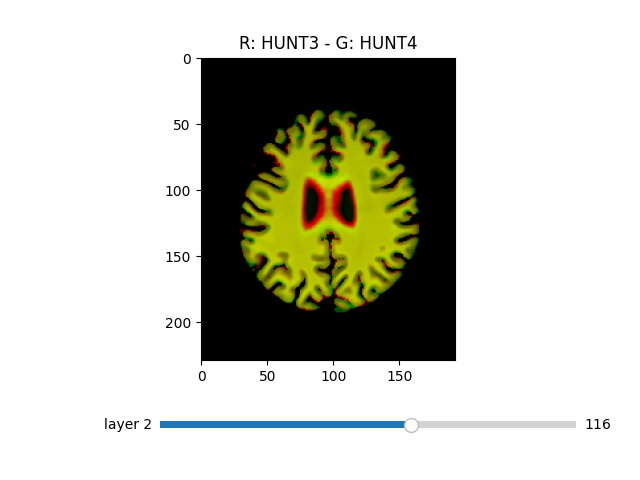

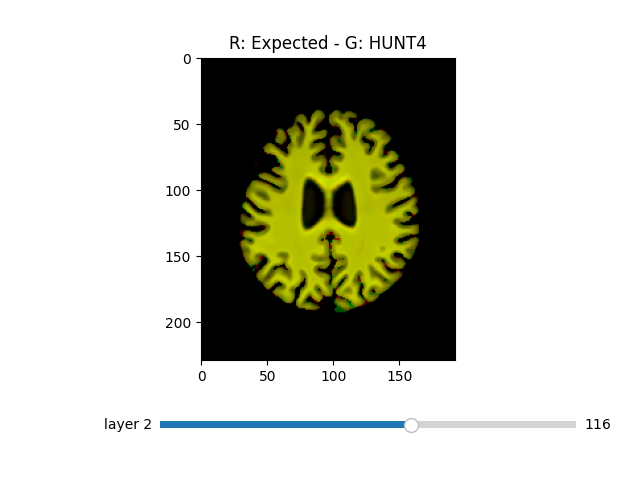

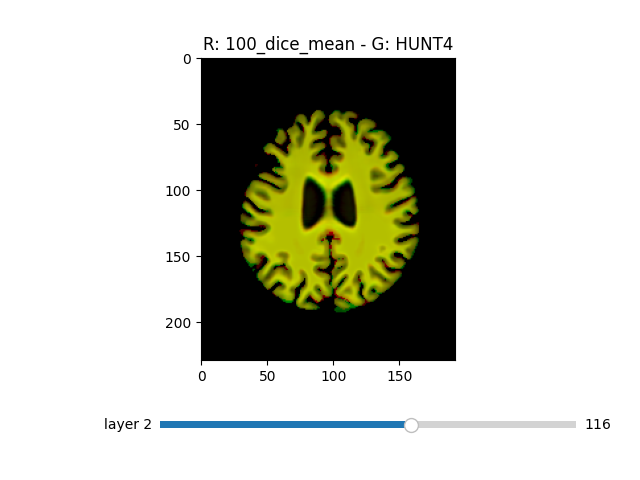

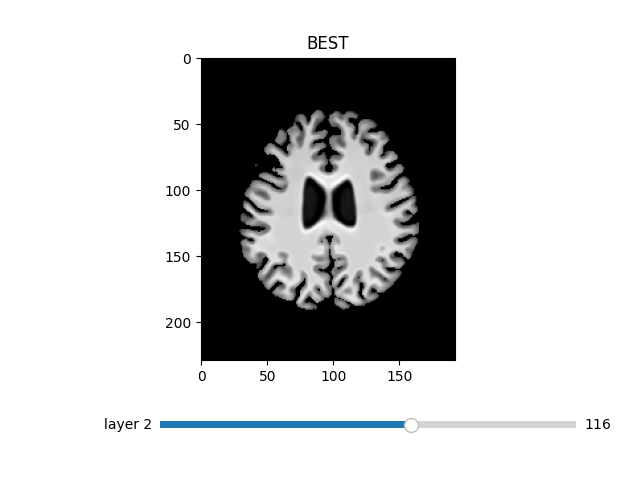

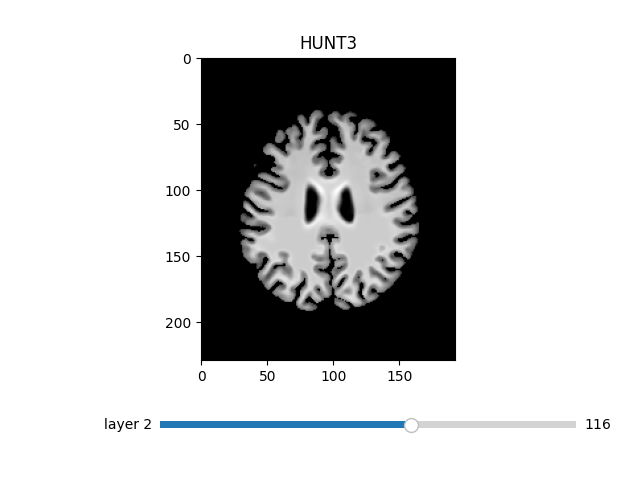

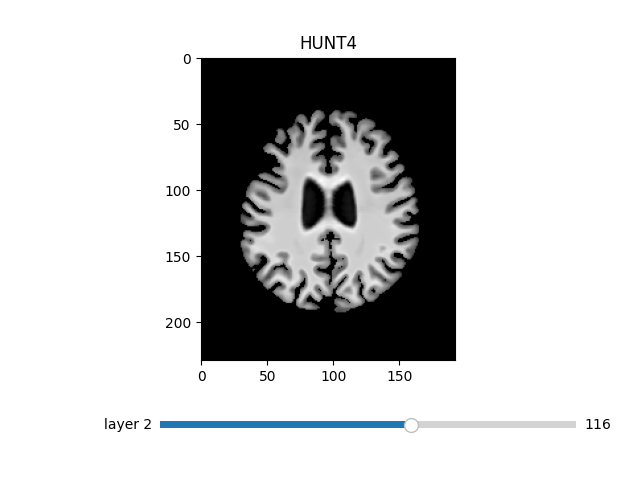

ID: 302: 08202


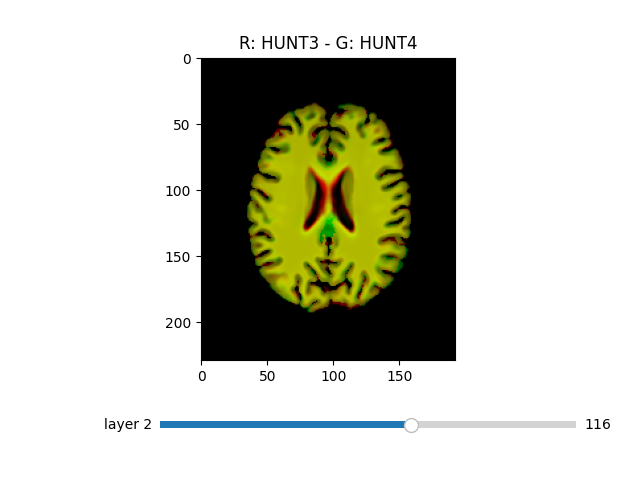

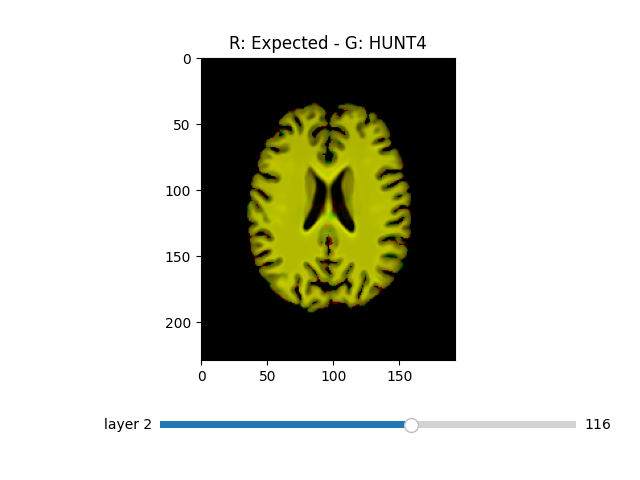

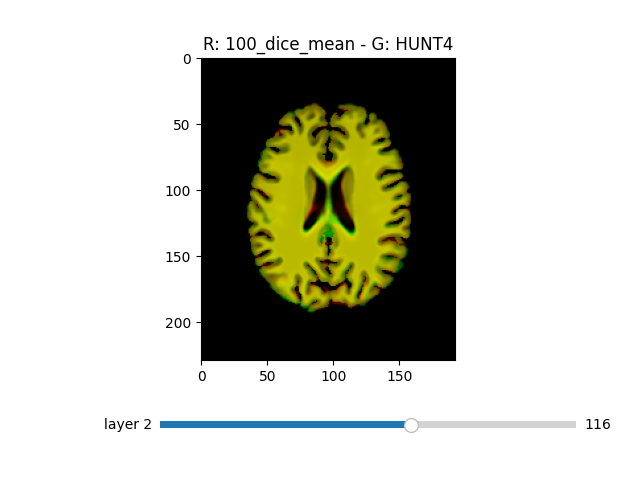

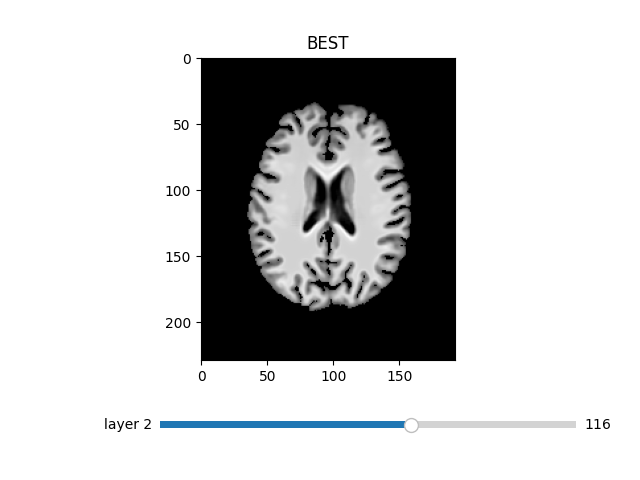

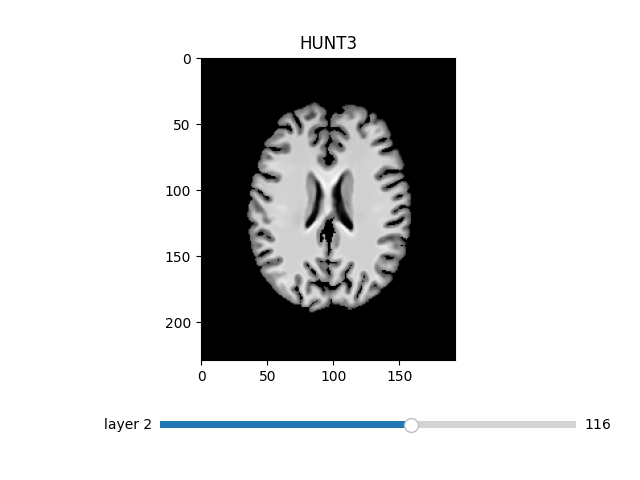

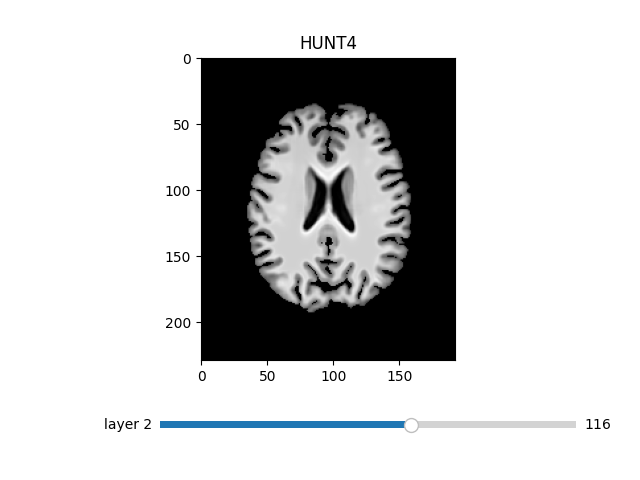

ID: 303: 08264


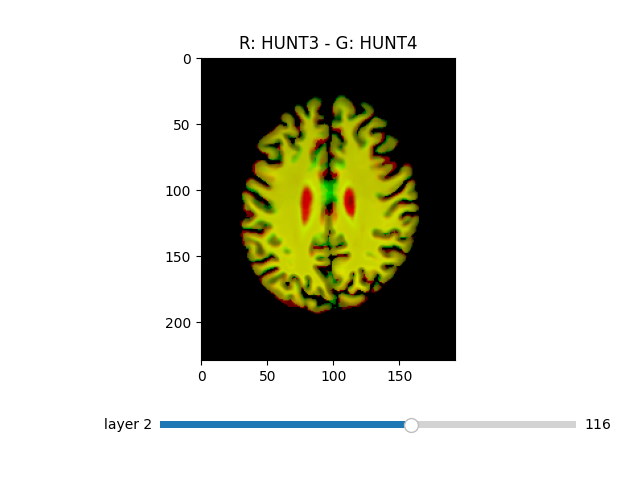

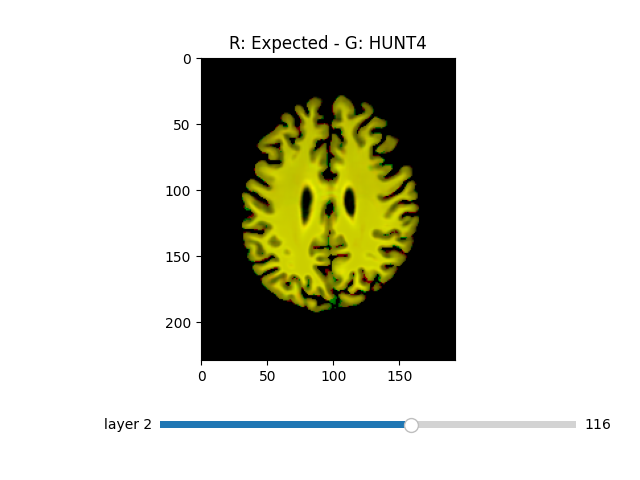

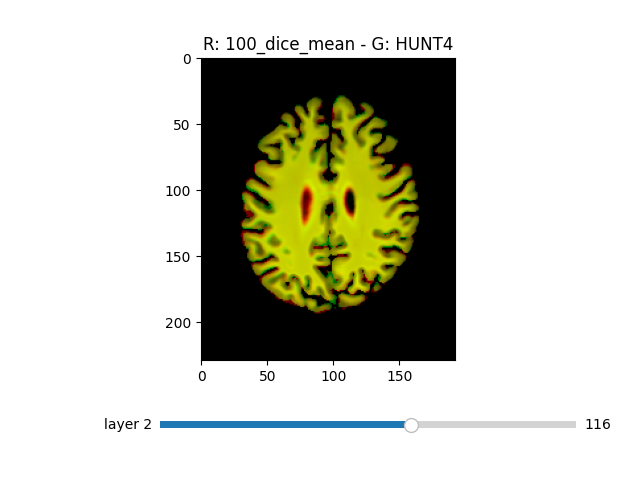

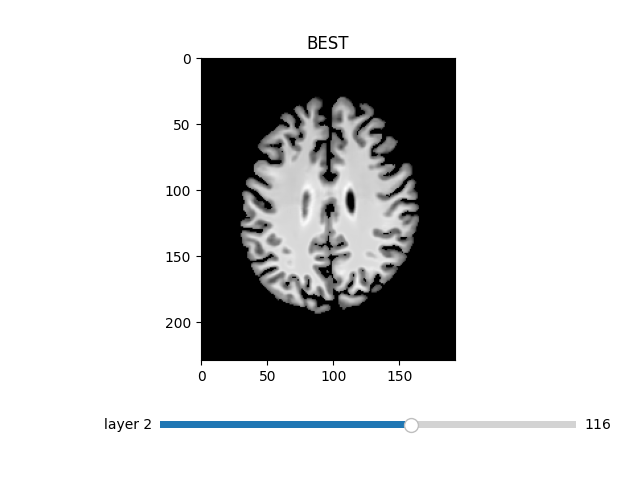

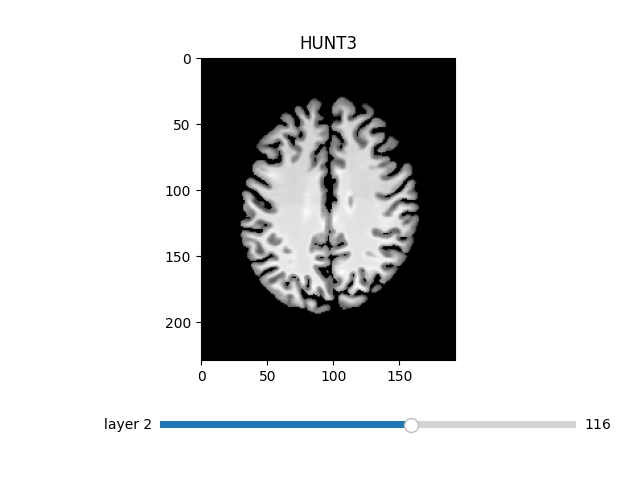

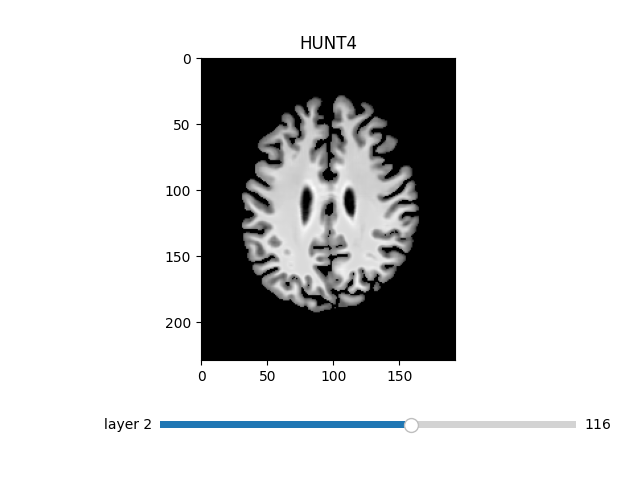

ID: 304: 08271


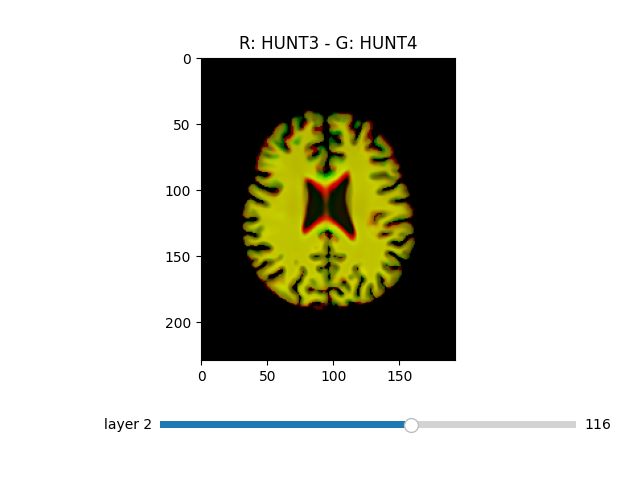

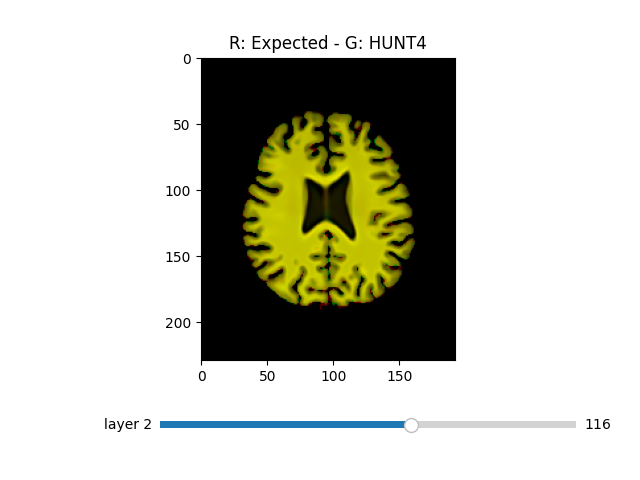

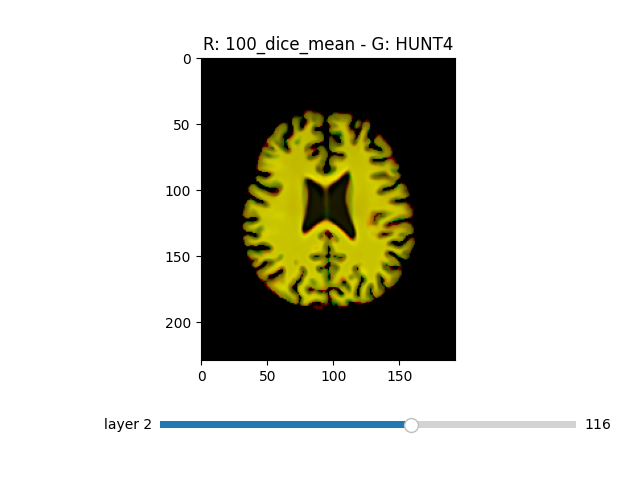

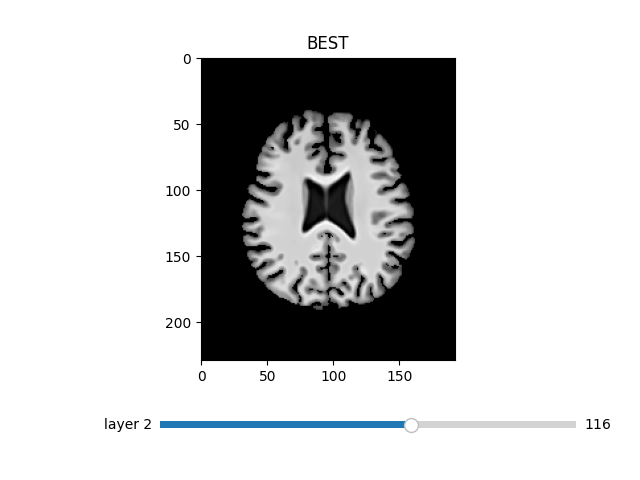

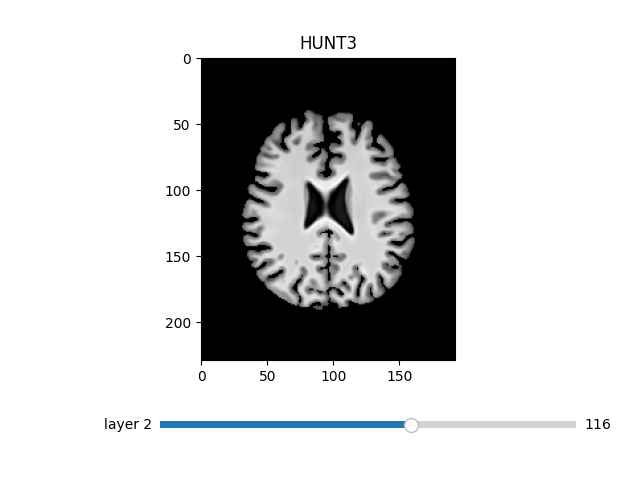

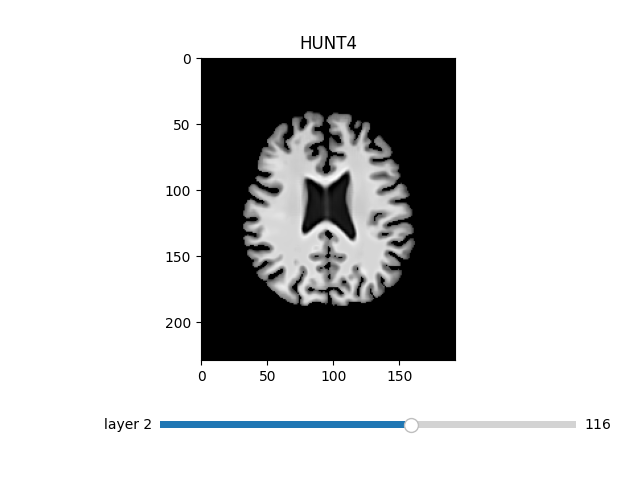

ID: 305: 08295


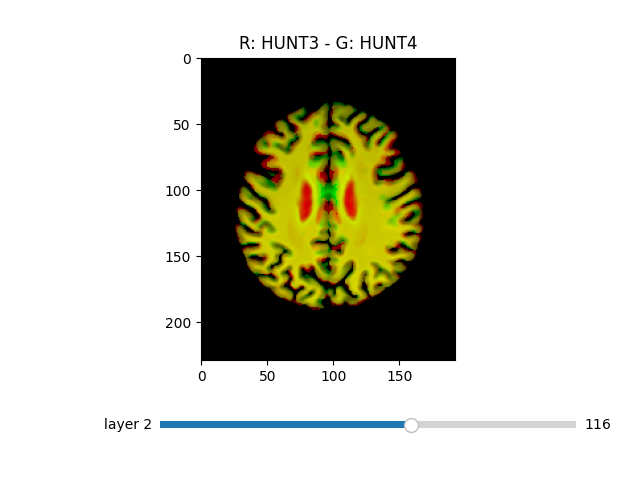

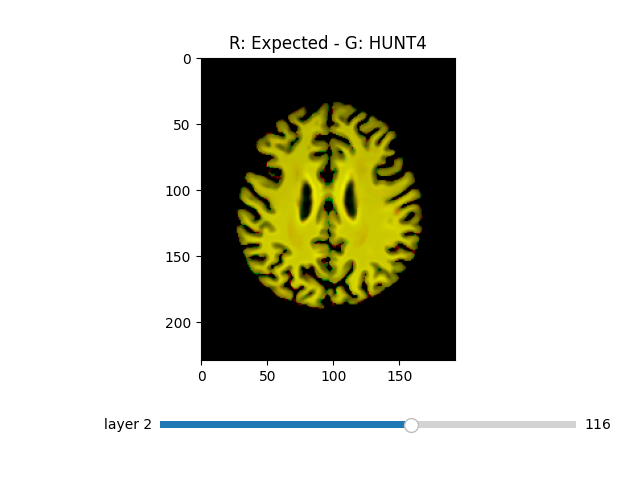

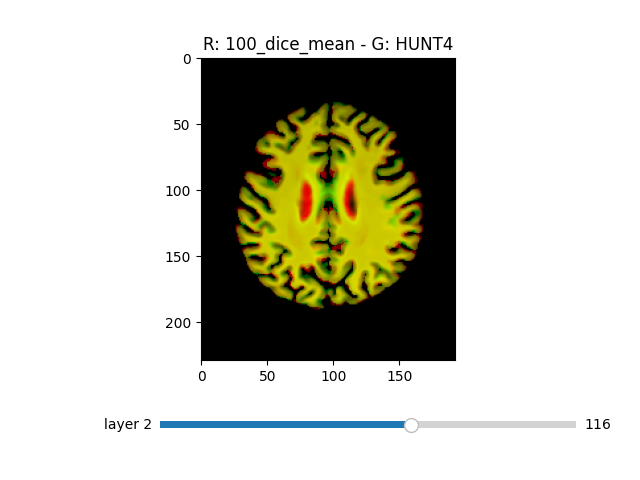

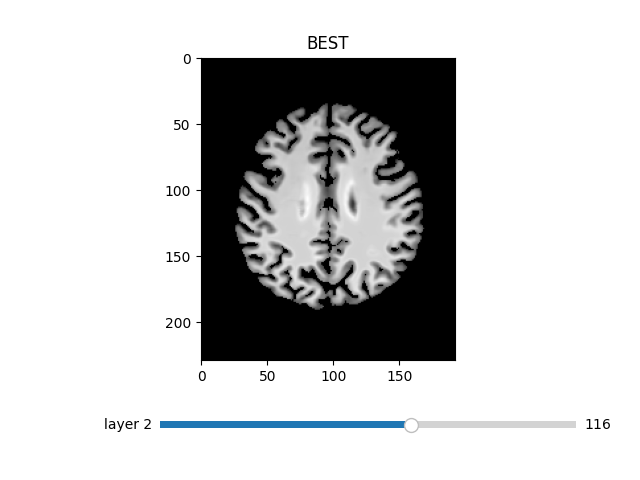

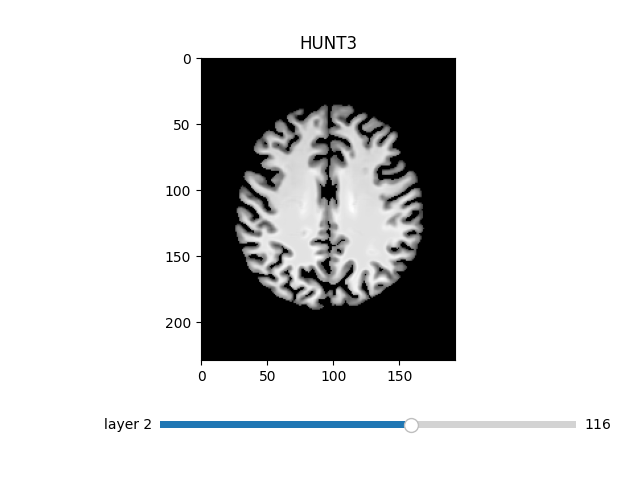

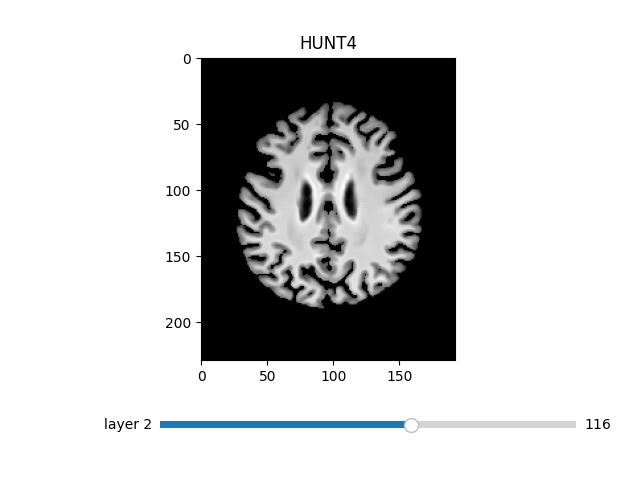

ID: 306: 08301


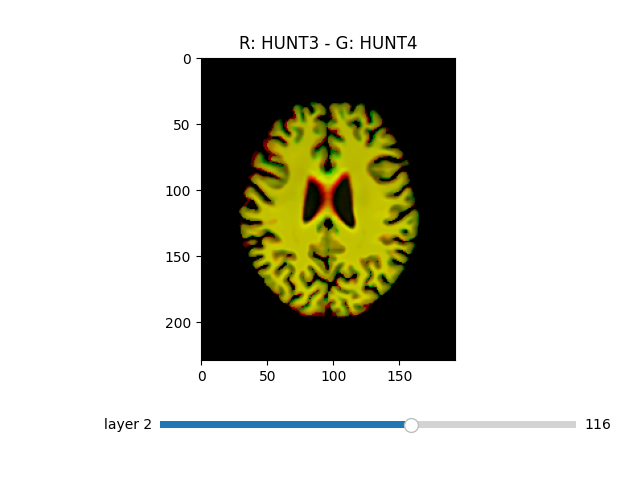

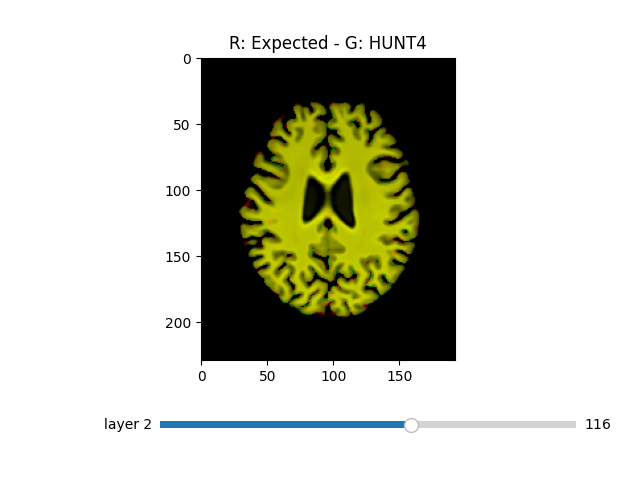

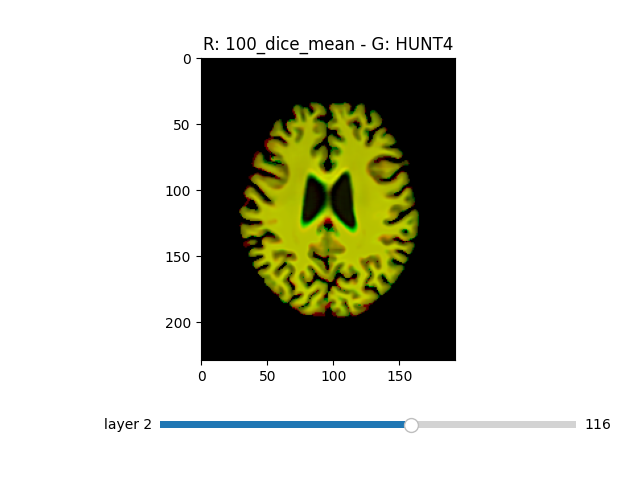

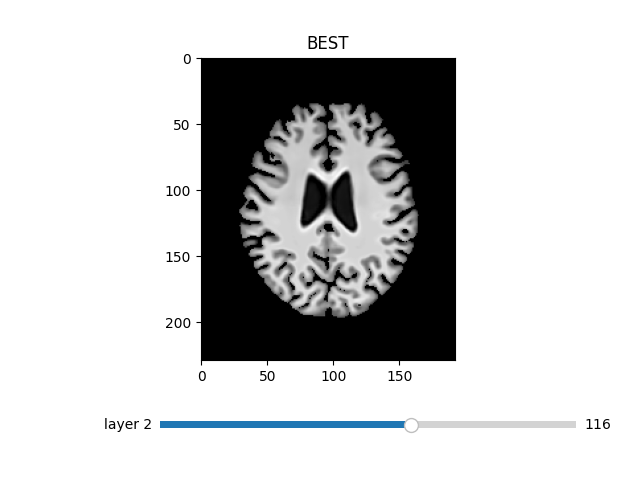

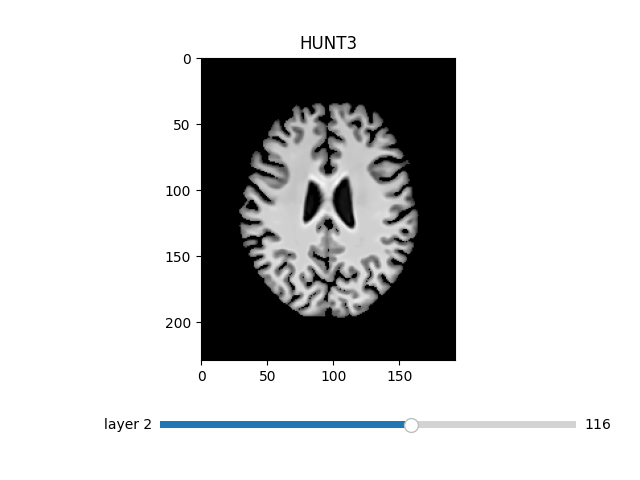

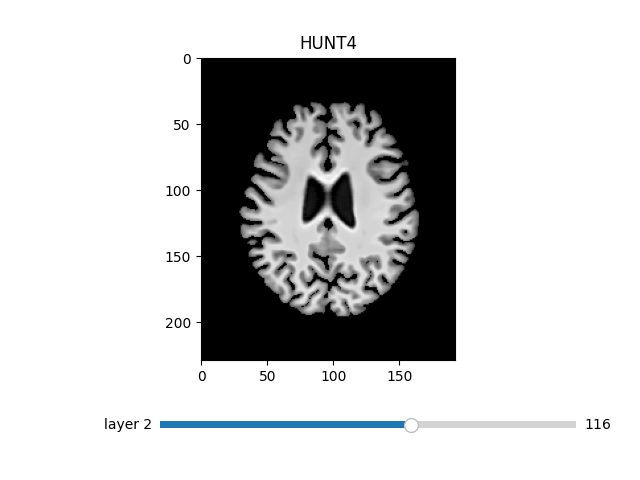

ID: 307: 08332


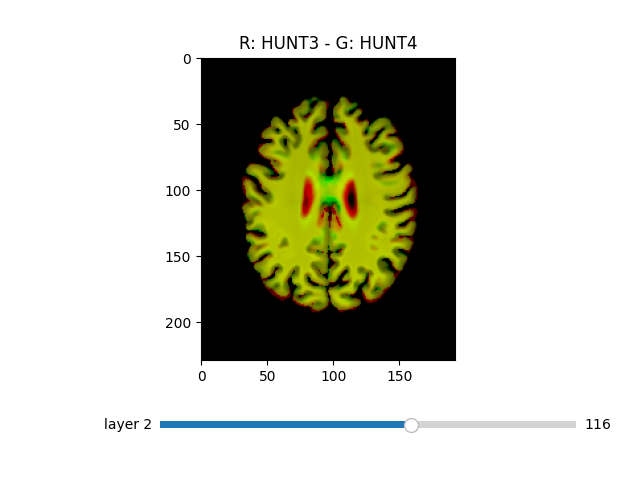

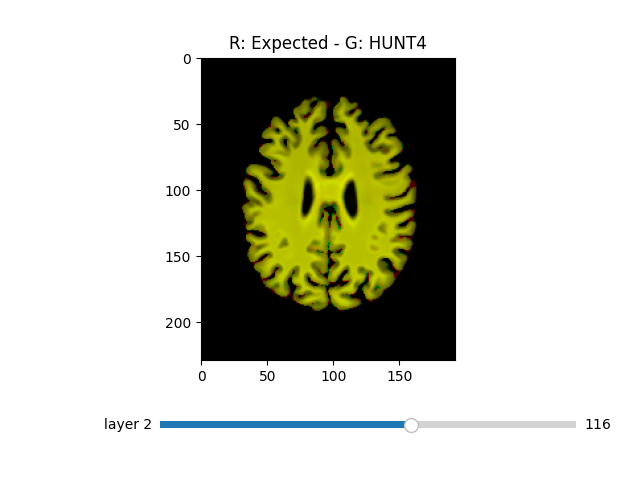

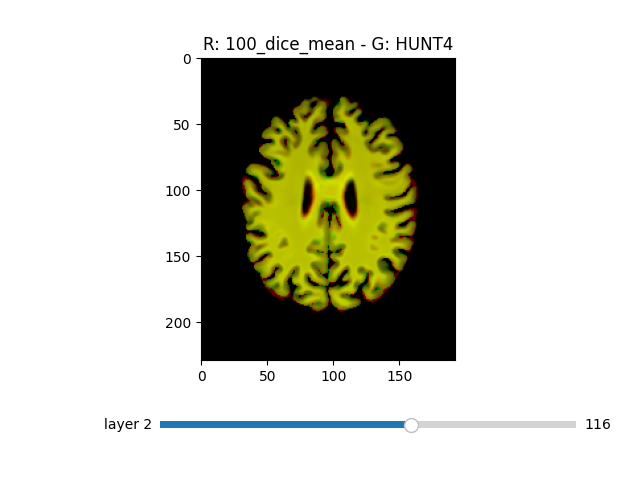

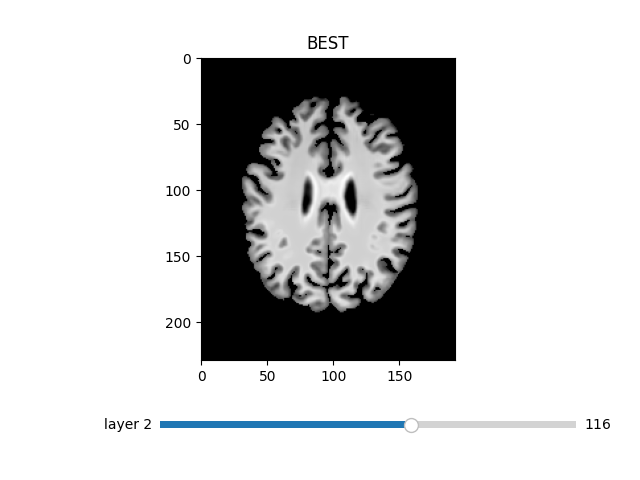

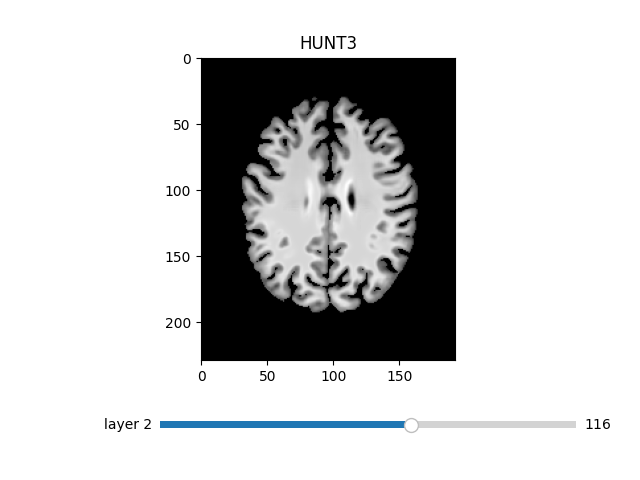

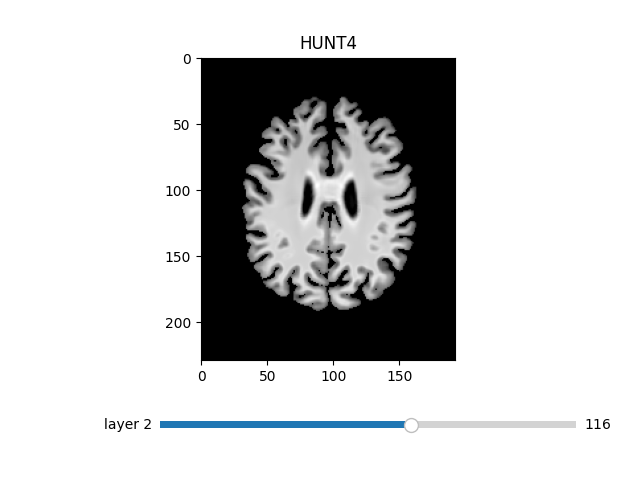

In [ ]:
current_plane = 116

def shows_rgb_img(img_fixed, img_reg, name=""):
    img_rgb = np.stack((img_reg, img_fixed, np.zeros_like(img_fixed)), axis=3)
    fc.imgshow_3D(name, img_rgb, current_plane=current_plane, transpose=True, flip_ax=0)

%matplotlib widget
for id_index, imgs in enumerate(imgs_list):
    print(f"ID: {id_indexs[id_index]}: {matchin_ids[id_indexs[id_index]]}")

    img_fixed, mask_fixed = imgs[0]
    img_moving, mask_moving = imgs[1]
    img_expected, mask_expected = imgs[2]
    shows_rgb_img(img_fixed, img_moving, "R: HUNT3 - G: HUNT4")
    shows_rgb_img(img_fixed, img_expected, "R: Expected - G: HUNT4")
    # for i, (img, mask) in enumerate(imgs[3:]):
    for i in [ordered_index_imgs[id_index][0]]:
        img, mask = imgs[i+1]
        shows_rgb_img(img_fixed, img, f"R: {df_first_columns_list[id_index][i]} - G: HUNT4")

        fc.imgshow_3D("BEST", img, current_plane=current_plane, transpose=True, flip_ax=0)

    fc.imgshow_3D("HUNT3", img_moving, current_plane=current_plane, transpose=True, flip_ax=0)
    fc.imgshow_3D("HUNT4", img_fixed, current_plane=current_plane, transpose=True, flip_ax=0)


ID: 301: 08189


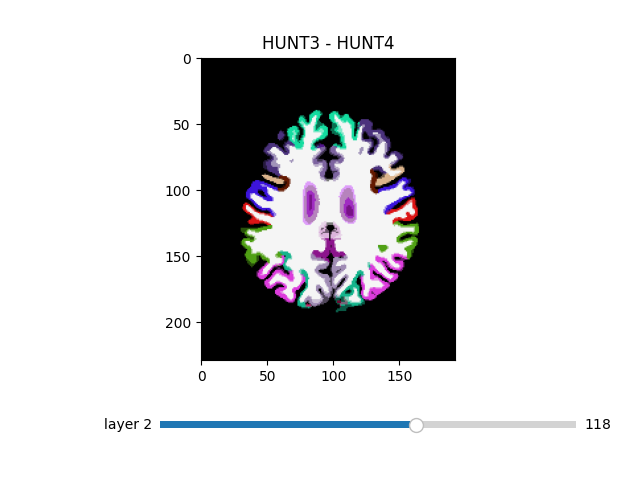

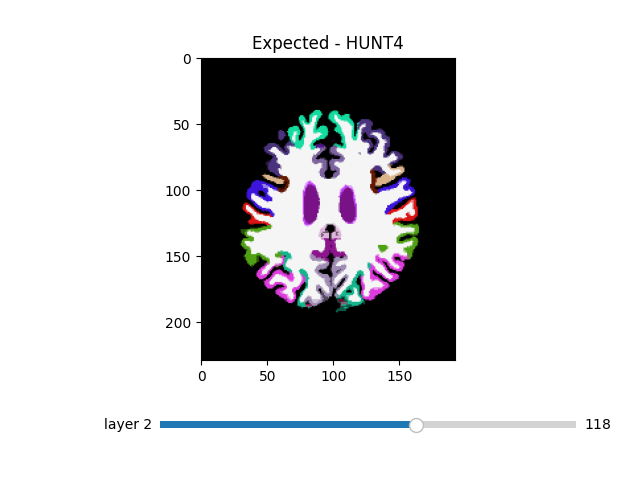

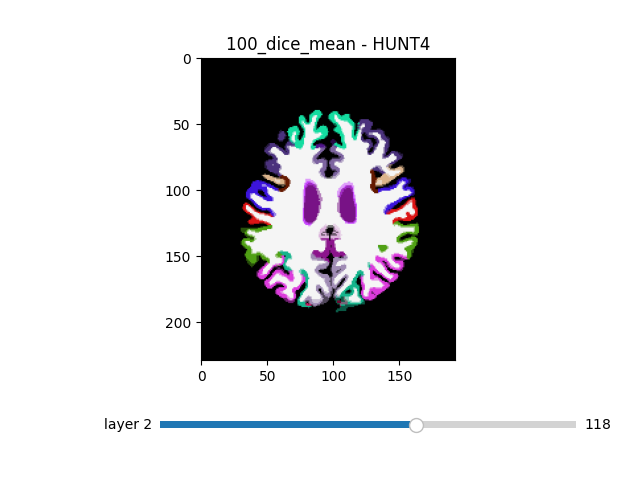

ID: 302: 08202


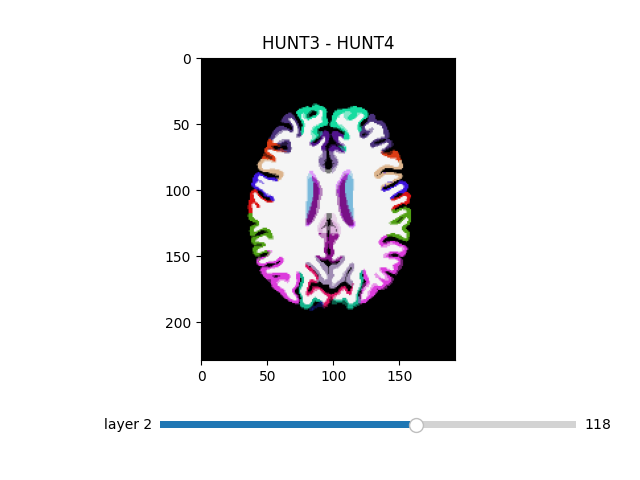

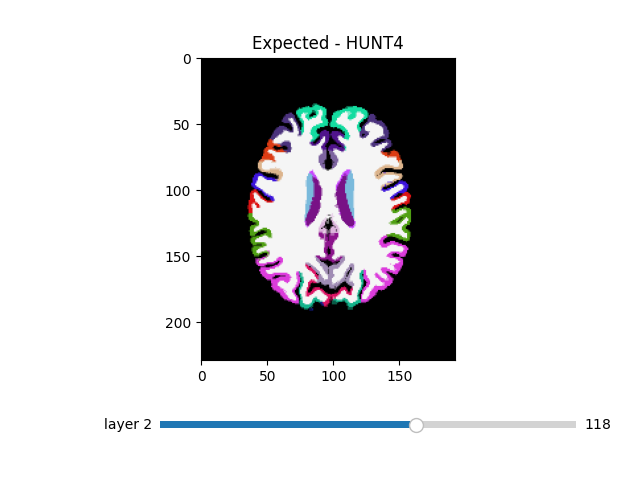

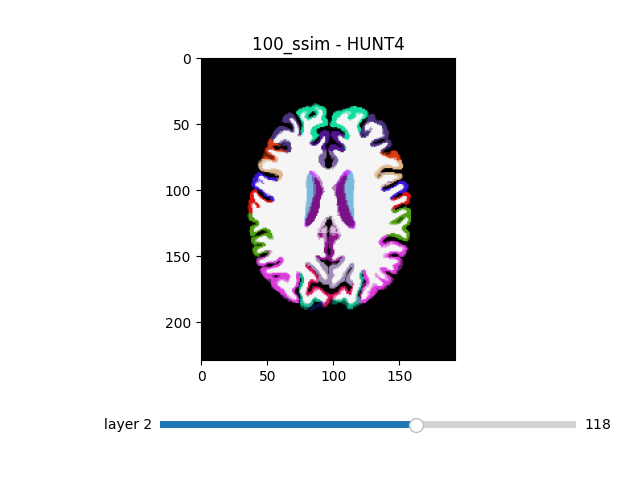

ID: 303: 08264


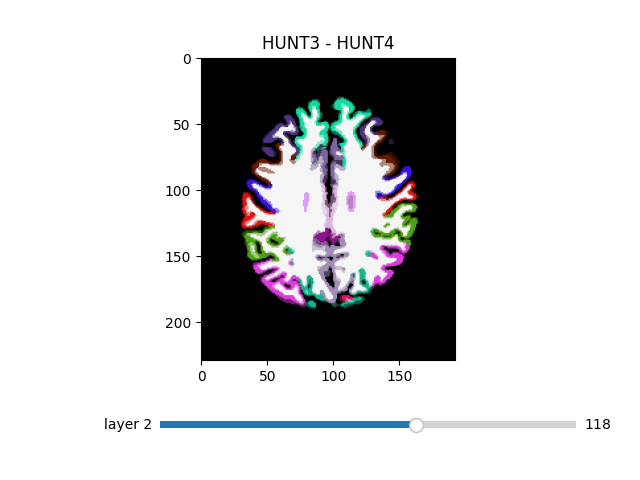

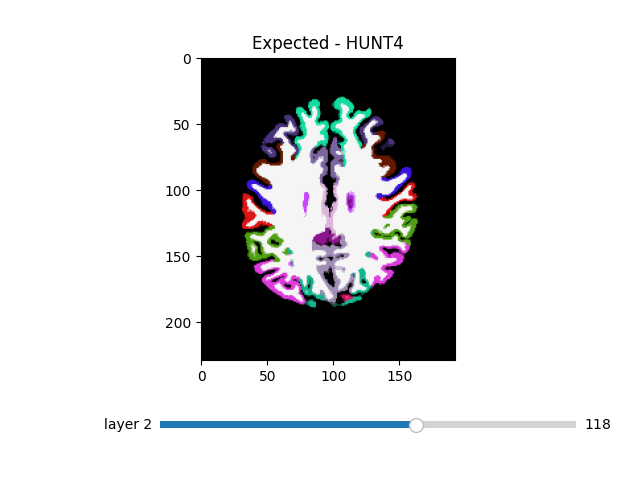

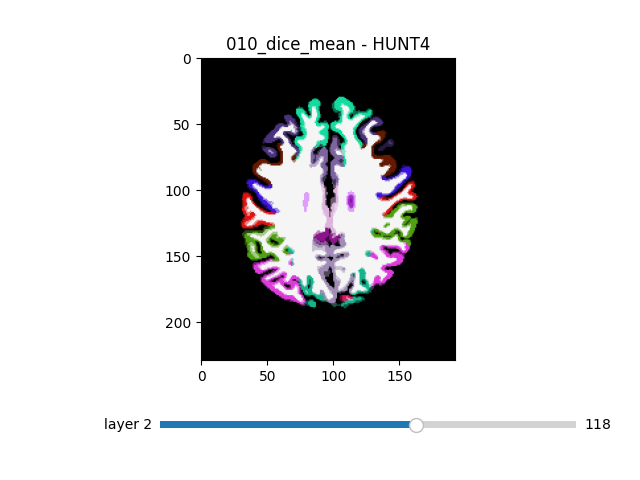

ID: 304: 08271


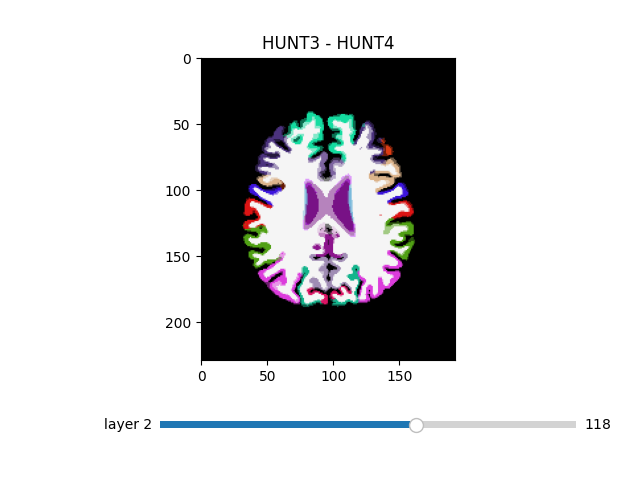

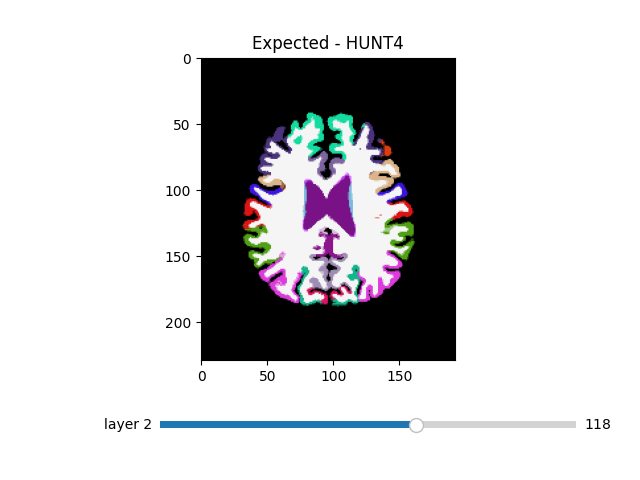

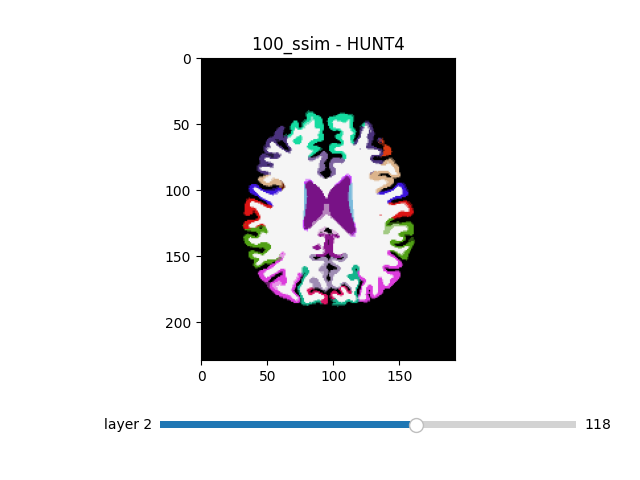

ID: 305: 08295


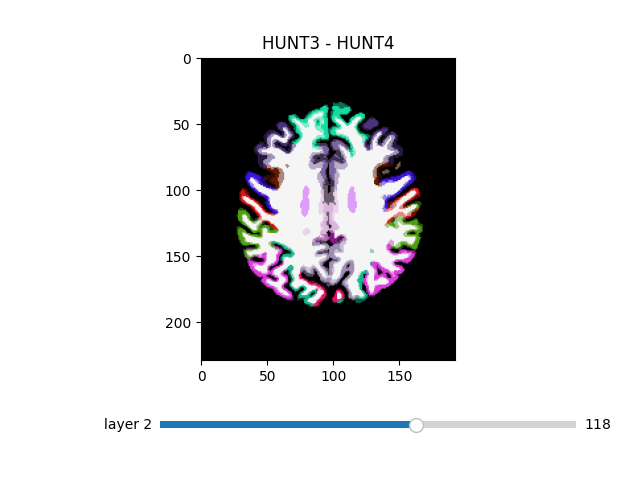

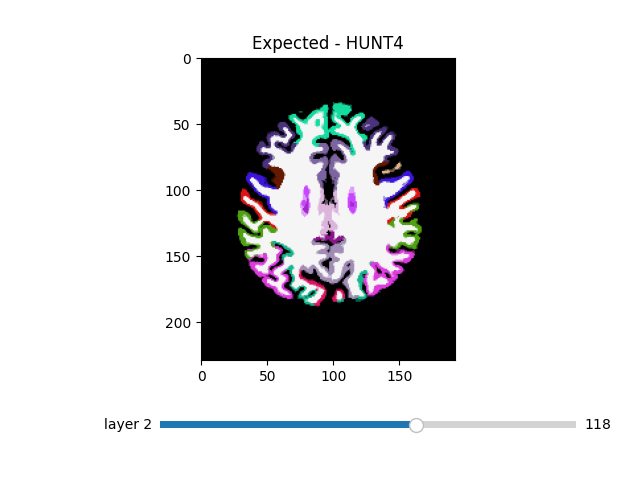

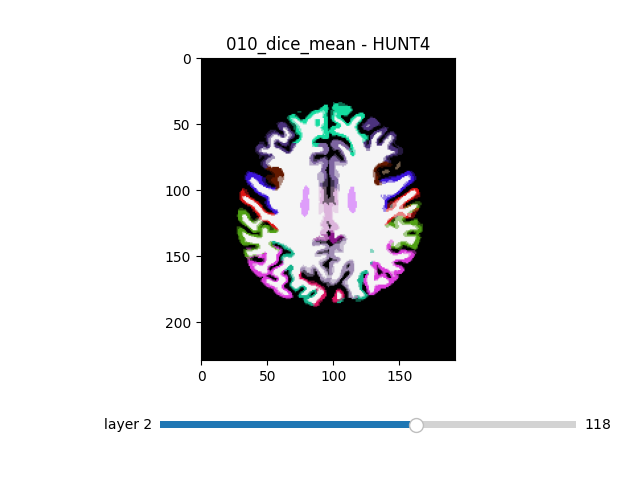

ID: 306: 08301


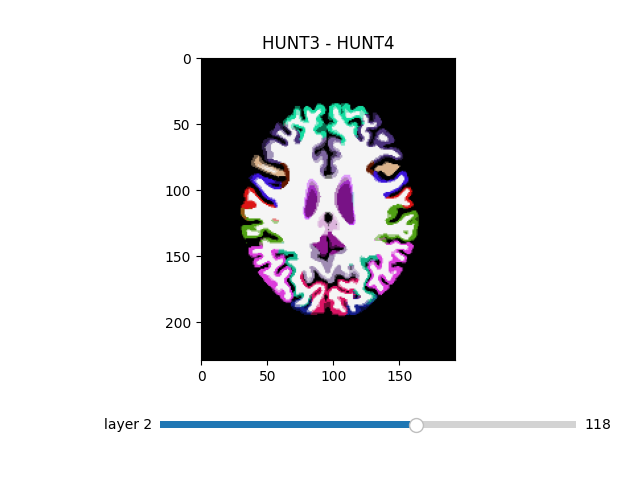

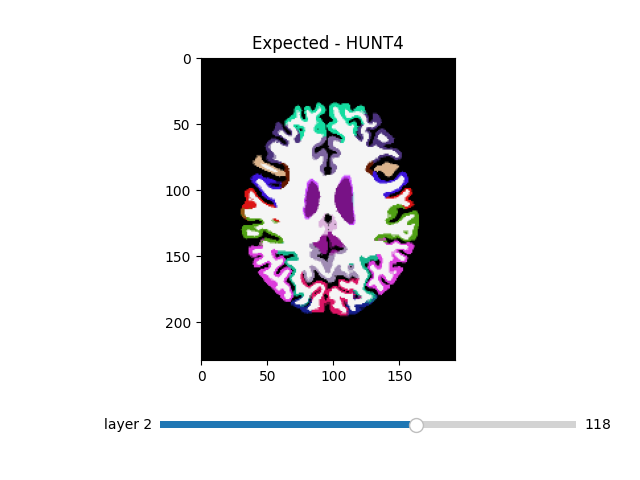

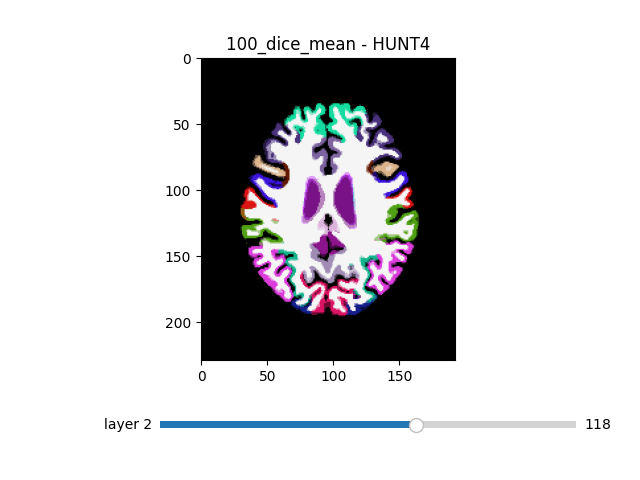

ID: 307: 08332


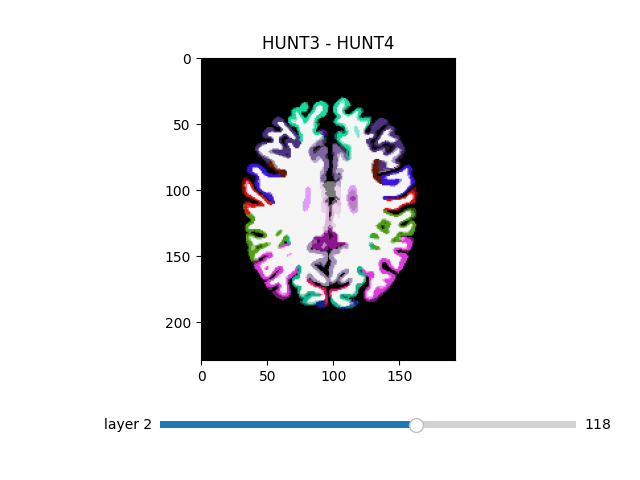

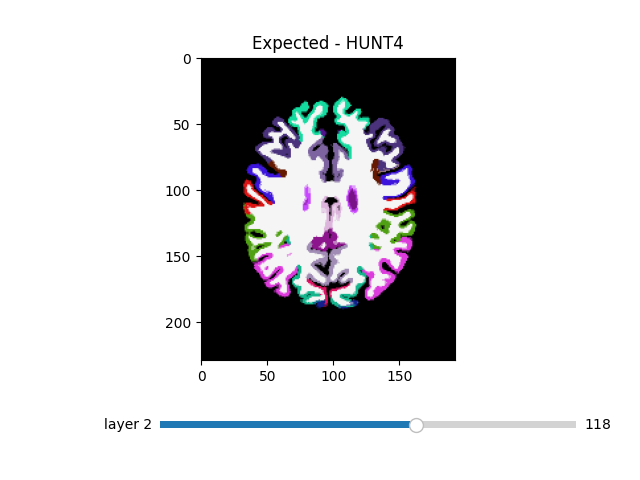

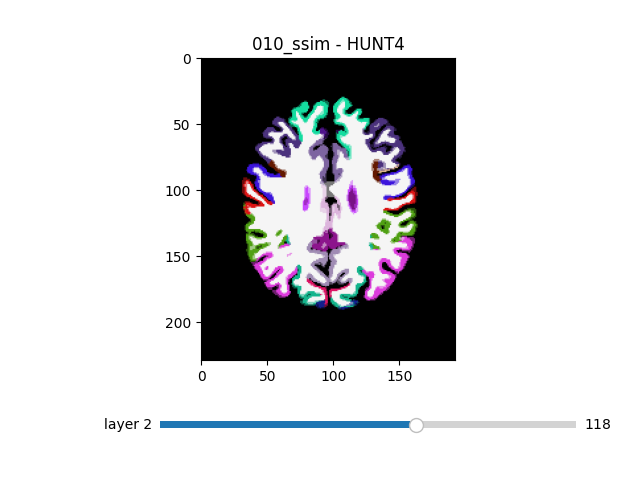

In [ ]:
import utils.util_freesurfer_segmentation as util_freesurfer

def show_overlap_rgb_seg(seg_fixed, seg_reg, name=""):
    seg_fixed_rgb = util_freesurfer.seg_to_rgbseg(seg_fixed).astype(np.float32)
    seg_reg_rgb = util_freesurfer.seg_to_rgbseg(seg_reg).astype(np.float32)

    overlap_original = ((seg_fixed_rgb + seg_reg_rgb) / 2).astype(np.uint8)
    fc.imgshow_3D(name, overlap_original, current_plane=118, transpose=True, flip_ax=0)


%matplotlib widget
for id_index, imgs in enumerate(imgs_list):
    print(f"ID: {id_indexs[id_index]}: {matchin_ids[id_indexs[id_index]]}")

    img_fixed, mask_fixed = imgs[0]
    img_moving, mask_moving = imgs[1]
    img_expected, mask_expected = imgs[2]
    show_overlap_rgb_seg(mask_fixed, mask_moving, "HUNT3 - HUNT4")
    show_overlap_rgb_seg(mask_fixed, mask_expected, "Expected - HUNT4")
    # for i, (img, mask) in enumerate(imgs[3:]):
    for i in [ordered_index_segs[id_index][0]]:
        img, mask = imgs[i+1]
        show_overlap_rgb_seg(mask_fixed, mask, f"{df_first_columns_list[id_index][i]} - HUNT4")



# Chat interpretation

### Mean for each method
- Método EXP:
  - SSIM: ~0.969883
  - NCC: ~0.986255
  - Mínimo DICE: ~0.631057
  - Máximo DICE: ~0.993632
  - DICE Promedio: ~0.856426

- Método 100_dice_mean:
  - SSIM: ~0.949831
  - NCC: ~0.944293
  - Mínimo DICE: ~0.363127
  - Máximo DICE: ~0.991598
  - DICE Promedio: ~0.806417

- Método 010_dice_mean:
  - SSIM: ~0.947474
  - NCC: ~0.945725
  - Mínimo DICE: ~0.319190
  - Máximo DICE: ~0.991011
  - DICE Promedio: ~0.794039

- Método 100_ssim:
  - SSIM: ~0.947266
  - NCC: ~0.943751
  - Mínimo DICE: ~0.322379
  - Máximo DICE: ~0.991114
  - DICE Promedio: ~0.802692

- Método 010_ssim:
  - SSIM: ~0.947103
  - NCC: ~0.947837
  - Mínimo DICE: ~0.359592
  - Máximo DICE: ~0.991279
  - DICE Promedio: ~0.792718


### Standart deviation for each method

- Método EXP:
  - SSIM: 0.003943
  - NCC: 0.033098
  - Mínimo DICE: 0.044866
  - Máximo DICE: 0.019727
  - DICE Promedio: 0.012466

- Método 100_dice_mean:
  - SSIM: 0.010783
  - NCC: 0.022442
  - Mínimo DICE: 0.113063
  - Máximo DICE: 0.015966
  - DICE Promedio: 0.018852

- Método 010_dice_mean:
  - SSIM: 0.007512
  - NCC: 0.010971
  - Mínimo DICE: 0.081844
  - Máximo DICE: 0.009546
  - DICE Promedio: 0.013167

- Método 100_ssim:
  - SSIM: 0.008370
  - NCC: 0.024446
  - Mínimo DICE: 0.124943
  - Máximo DICE: 0.013768
  - DICE Promedio: 0.018038

- Método 010_ssim:
  - SSIM: 0.007071
  - NCC: 0.012050
  - Mínimo DICE: 0.102624
  - Máximo DICE: 0.014010
  - DICE Promedio: 0.015706





Based on the analysis of mean and standard deviation of the metrics, here's the ranking of the registration methods from best to worst:

1. EXP
2. 100_dice_mean
3. 010_ssim
4. 100_ssim
5. 010_dice_mean

This ranking is based on the combination of high mean values across the metrics (indicating good performance) and low standard deviations (indicating consistency in performance). However, the choice of the best method ultimately depends on the specific requirements and priorities of your application.
